In [1]:
import torch
import matplotlib.pyplot as plt
import torchvision

from models import NeuralNetworkClassificationModel

from learners import ClassificationLearner

from utilities import plot_images_and_labels, plot_training_process


device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print('device:', device)

device: cpu


In [2]:
random_seed = 1

batch_size_train = 64
batch_size_test = 1000
epochs = 5
learning_rates = [0.01, 0.1, 0.15, 0.2, 0.25]

transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor()
])

train_dataset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)

print("train data shape:", tuple(train_dataset.data.shape))
print("train targets shape:", tuple(train_dataset.targets.shape))
print("test data shape:", tuple(test_dataset.data.shape))
print("test targets shape:", tuple(test_dataset.targets.shape))
print()

train data shape: (60000, 28, 28)
train targets shape: (60000,)
test data shape: (10000, 28, 28)
test targets shape: (10000,)



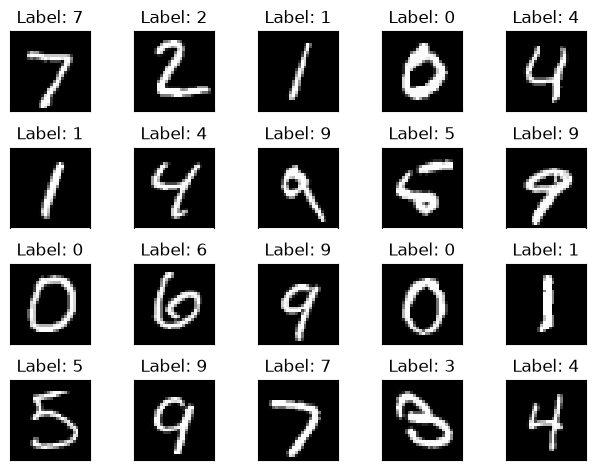

In [3]:
train_subset, valid_subset = torch.utils.data.random_split(train_dataset, [0.8, 0.2])

# create dataloaders that sample batches from the training, validation and test datasets
train_dataloader = torch.utils.data.DataLoader(dataset=train_subset, batch_size=batch_size_train, shuffle=True)
valid_dataloader = torch.utils.data.DataLoader(dataset=valid_subset, batch_size=batch_size_test, shuffle=False)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size_test, shuffle=False)

# plot a sample of images and labels
sample_data, sample_targets = next(iter(test_dataloader))
plot_images_and_labels(sample_data, sample_targets)

In [4]:
results = {}
for lr in learning_rates:
    print(f"--- lr={lr} ---")

    torch.manual_seed(random_seed)
    torch.cuda.manual_seed(random_seed)

    model = NeuralNetworkClassificationModel()
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(),lr)

    learner = ClassificationLearner(model, criterion, optimizer)
    train_losses, valid_losses, valid_accuracies = learner.train(train_dataloader, valid_dataloader, epochs, device)

    min_valid_loss = min(valid_losses)
    min_valid_loss_index = valid_losses.index(min_valid_loss)
    min_valid_accuracy = valid_accuracies[min_valid_loss_index]

    learner.load("leader")

    test_loss, test_accuracy = learner.test(test_dataloader, device)

    results[lr] = {
        "train_losses": train_losses,
        "valid_losses": valid_losses,
        "valid_accuracies": valid_accuracies,
        "min_valid_loss": min_valid_loss,
        "valid_accuracy": min_valid_accuracy,
    }

    print(f"lr={lr}: valid loss = {min_valid_loss:.4f}, valid accuracy = {100 * min_valid_accuracy:.2f}%")
    print()


--- lr=0.01 ---
train epoch [1/5]:	train loss = 1.8846	valid loss = 1.0760	valid accuracy = 74.72%
train epoch [2/5]:	train loss = 0.6937	valid loss = 0.5136	valid accuracy = 86.32%
train epoch [3/5]:	train loss = 0.4499	valid loss = 0.4105	valid accuracy = 88.42%
train epoch [4/5]:	train loss = 0.3825	valid loss = 0.3668	valid accuracy = 89.61%
train epoch [5/5]:	train loss = 0.3461	valid loss = 0.3401	valid accuracy = 90.42%

lr=0.01: valid loss = 0.3401, valid accuracy = 90.42%

--- lr=0.1 ---
train epoch [1/5]:	train loss = 0.5572	valid loss = 0.2636	valid accuracy = 92.72%
train epoch [2/5]:	train loss = 0.2106	valid loss = 0.1827	valid accuracy = 94.95%
train epoch [3/5]:	train loss = 0.1431	valid loss = 0.1387	valid accuracy = 96.03%
train epoch [4/5]:	train loss = 0.1090	valid loss = 0.1395	valid accuracy = 95.88%
train epoch [5/5]:	train loss = 0.0874	valid loss = 0.1192	valid accuracy = 96.42%

lr=0.1: valid loss = 0.1192, valid accuracy = 96.42%

--- lr=0.15 ---
train epoch 

In [5]:
print(f"{'lr':>8} | {'valid loss':>10} | {'valid acc':>9}")
print("-" * 34)
for lr, r in results.items():
    print(f"{lr:>8} | {r['min_valid_loss']:>10.4f} | {100 * r['valid_accuracy']:>8.2f}%")

best_lr = min(results, key=lambda lr: results[lr]["min_valid_loss"])
print(f"\nBest learning rate: {best_lr}")

      lr | valid loss | valid acc
----------------------------------
    0.01 |     0.3401 |    90.42%
     0.1 |     0.1192 |    96.42%
    0.15 |     0.1066 |    96.97%
     0.2 |     0.1024 |    97.17%
    0.25 |     0.0981 |    97.23%

Best learning rate: 0.25


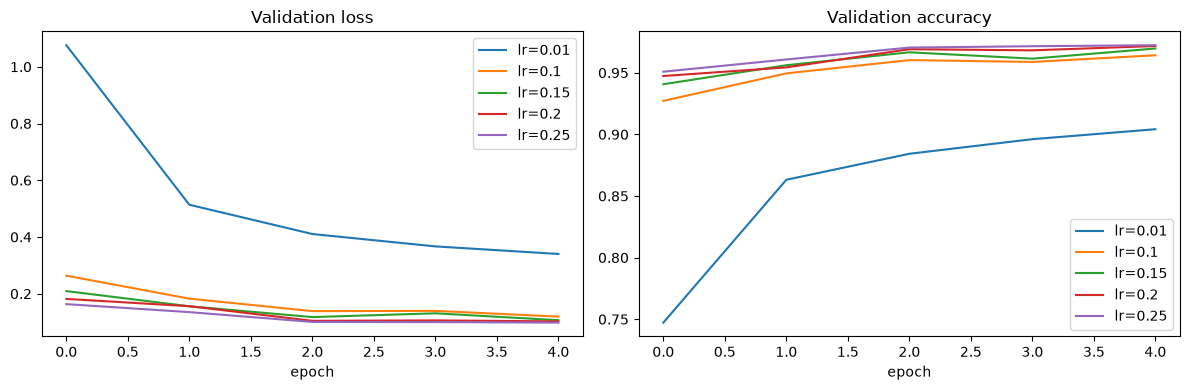

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for lr, r in results.items():
    axes[0].plot(r["valid_losses"], label=f"lr={lr}")
    axes[1].plot(r["valid_accuracies"], label=f"lr={lr}")

axes[0].set_title("Validation loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

train epoch [1/50]:	train loss = 0.3865	valid loss = 0.1633	valid accuracy = 95.08%
train epoch [2/50]:	train loss = 0.1329	valid loss = 0.1351	valid accuracy = 96.08%
train epoch [3/50]:	train loss = 0.0923	valid loss = 0.1005	valid accuracy = 97.04%
train epoch [4/50]:	train loss = 0.0708	valid loss = 0.1000	valid accuracy = 97.15%
train epoch [5/50]:	train loss = 0.0545	valid loss = 0.0981	valid accuracy = 97.23%
train epoch [6/50]:	train loss = 0.0439	valid loss = 0.0991	valid accuracy = 97.22%
train epoch [7/50]:	train loss = 0.0345	valid loss = 0.0864	valid accuracy = 97.53%
train epoch [8/50]:	train loss = 0.0298	valid loss = 0.0944	valid accuracy = 97.50%
train epoch [9/50]:	train loss = 0.0221	valid loss = 0.0928	valid accuracy = 97.69%
train epoch [10/50]:	train loss = 0.0179	valid loss = 0.0896	valid accuracy = 97.78%
train epoch [11/50]:	train loss = 0.0132	valid loss = 0.0919	valid accuracy = 98.02%
train epoch [12/50]:	train loss = 0.0098	valid loss = 0.0932	valid accurac

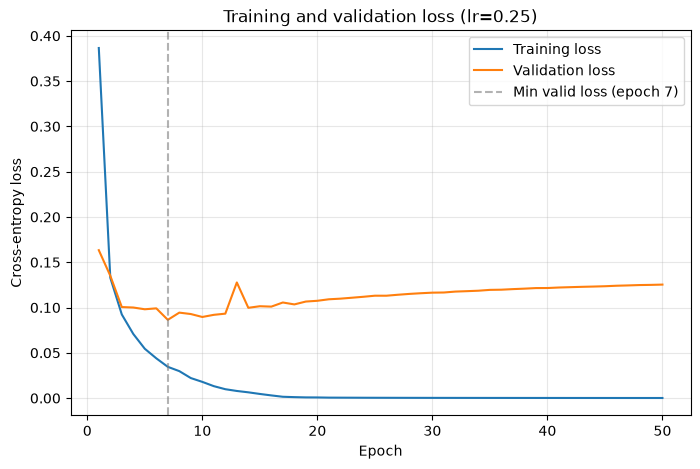

In [7]:
epochs = 50

torch.manual_seed(random_seed)
torch.cuda.manual_seed(random_seed)

model = NeuralNetworkClassificationModel()
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), best_lr)

learner = ClassificationLearner(model, criterion, optimizer)
train_losses, valid_losses, valid_accuracies = learner.train(
    train_dataloader, valid_dataloader, epochs, device
)

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, label="Training loss")
plt.plot(range(1, epochs + 1), valid_losses, label="Validation loss")

best_epoch = valid_losses.index(min(valid_losses)) + 1
plt.axvline(best_epoch, color="gray", linestyle="--", alpha=0.6,
            label=f"Min valid loss (epoch {best_epoch})")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title(f"Training and validation loss (lr={best_lr})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

First reached 97.35% validation accuracy at epoch 7
  train loss: 0.0345
  valid loss: 0.0864
  valid acc:  97.53%


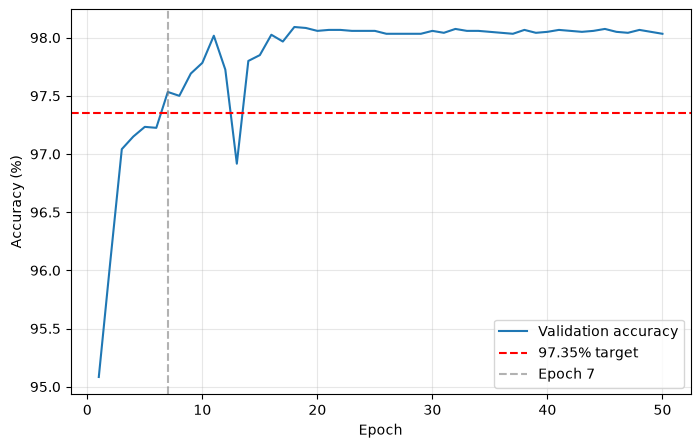

In [8]:
target = 0.9735

reached = next((i + 1 for i, a in enumerate(valid_accuracies) if a >= target), None)

if reached is None:
    print(f"Target of {100*target:.2f}% was never reached "
          f"(max = {100*max(valid_accuracies):.2f}%).")
else:
    i = reached - 1
    print(f"First reached {100*target:.2f}% validation accuracy at epoch {reached}")
    print(f"  train loss: {train_losses[i]:.4f}")
    print(f"  valid loss: {valid_losses[i]:.4f}")
    print(f"  valid acc:  {100*valid_accuracies[i]:.2f}%")

# accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), [100 * a for a in valid_accuracies], label="Validation accuracy")
plt.axhline(100 * target, color="red", linestyle="--", label="97.35% target")
if reached:
    plt.axvline(reached, color="gray", linestyle="--", alpha=0.6, label=f"Epoch {reached}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()